## 0 — Setup

In your terminal, in the environment used by Jupyter:

```bash
python -m pip install -U mlx numpy matplotlib jupyter
```

PyTorch with MPS is optional for further comparisons; our kernel will use **MLX/Metal**, not PyTorch MPS.

In [4]:
# import sys
# import subprocess

# result = subprocess.run(
#     [sys.executable, "-m", "pip", "install", "-U", "mlx"],
#     capture_output=True,
#     text=True,
# )

# print("Return code:", result.returncode)
# print(result.stdout)
# print(result.stderr)

In [5]:
import math, platform, time
import numpy as np
import matplotlib.pyplot as plt

print('Platform:', platform.platform())
print('NumPy:', np.__version__)
try:
    import mlx.core as mx
    MLX_OK = bool(mx.metal.is_available())
    print('MLX Metal available:', MLX_OK)
except (ImportError, RuntimeError, AttributeError) as exc:
    mx = None
    MLX_OK = False
    print('MLX Metal unavailable here:', repr(exc))
print('Run GPU sections on your Apple M5. CPU explanations/plots work everywhere.')

Platform: macOS-27.0.1-arm64-arm-64bit
NumPy: 2.5.4
MLX Metal available: True
Run GPU sections on your Apple M5. CPU explanations/plots work everywhere.


## 1 — Mathematical recap: online softmax per query

For a query $q_i$, let $s_{ij}=q_i\cdot k_j/\sqrt{d}$. For keys visited so far, we keep:

$$
m_i=\max_j s_{ij},\qquad \ell_i=\sum_j e^{s_{ij}-m_i},\qquad
a_i=\sum_j e^{s_{ij}-m_i}v_j.
$$

For the next key tile $J_b$:

$$
m_b=\max_{j\in J_b}s_{ij}, \quad m'=\max(m,m_b), \quad \alpha=e^{m-m'},
$$

$$
\ell'=\alpha\ell+\sum_{j\in J_b}e^{s_{ij}-m'},\qquad
a'=\alpha a+\sum_{j\in J_b}e^{s_{ij}-m'}v_j,
$$

and $o_i=a_i/\ell_i$ at the end. If causal, only keys $j\le i$ contribute. Empty tiles must not trigger $-\infty-(-\infty)$.

In [6]:
def dense_attention(q, k, v, causal=False):
    """CPU oracle; intentionally materializes N*N scores."""
    d = q.shape[-1]
    scores = q @ k.T / np.sqrt(d)
    if causal:
        scores = np.where(np.arange(k.shape[0])[None, :] <= np.arange(q.shape[0])[:, None], scores, -np.inf)
    probs = np.exp(scores - scores.max(axis=1, keepdims=True))
    probs = probs / probs.sum(axis=1, keepdims=True)
    return probs @ v


def streaming_attention_cpu(q, k, v, block_k=16, causal=False):
    """CPU reference matching the *per-row* streaming Metal v1 design."""
    n, d = q.shape
    assert k.shape == v.shape == q.shape and block_k > 0
    out = np.empty_like(q)
    for i in range(n):
        m, ell, acc = -np.inf, 0., np.zeros(d)
        for start in range(0, n, block_k):
            end = min(n, start + block_k)
            js = np.arange(start, end)
            if causal:
                js = js[js <= i]
            if len(js) == 0:
                continue
            s = (k[js] @ q[i]) / np.sqrt(d)
            m_next = max(m, float(s.max()))
            alpha = 0. if not np.isfinite(m) else np.exp(m - m_next)
            w = np.exp(s - m_next)
            ell = alpha * ell + w.sum()
            acc = alpha * acc + w @ v[js]
            m = m_next
        out[i] = acc / ell
    return out

rng = np.random.default_rng(42)
for n, d in [(5, 8), (17, 16), (33, 32)]:
    q, k, v = (rng.normal(size=(n, d)).astype(np.float32) for _ in range(3))
    for causal in (False, True):
        for bk in (1, 7, 16):
            err = np.max(np.abs(streaming_attention_cpu(q,k,v,bk,causal) - dense_attention(q,k,v,causal)))
            assert err < 1e-5, (n,d,bk,causal,err)
print('CPU oracle matches tiled per-row algorithm across odd lengths, tile sizes, and causal modes.')

CPU oracle matches tiled per-row algorithm across odd lengths, tile sizes, and causal modes.


## 2 — Visualize the GPU thread and memory work

Each horizontal row is computed by one Metal thread. The same K/V block is *reloaded by many threads* in this version — this is the central performance limitation we will fix in Notebook 05.

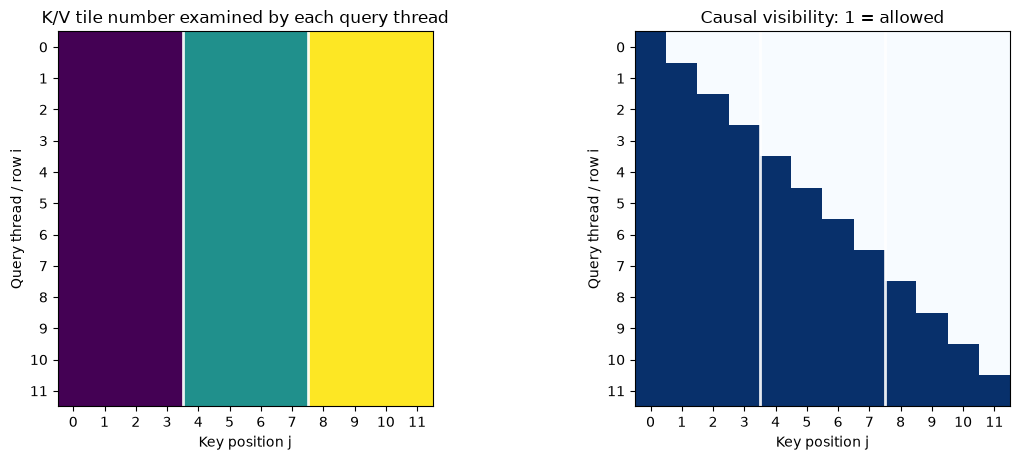

In [7]:
N, BK = 12, 4
fig, axs = plt.subplots(1, 2, figsize=(12, 4.7))
steps = np.tile(np.arange(N)//BK, (N,1))
axs[0].imshow(steps, cmap='viridis', interpolation='nearest', aspect='equal')
axs[0].set_title('K/V tile number examined by each query thread')
mask = (np.arange(N)[None,:] <= np.arange(N)[:,None]).astype(float)
axs[1].imshow(mask, cmap='Blues', vmin=0, vmax=1, interpolation='nearest', aspect='equal')
axs[1].set_title('Causal visibility: 1 = allowed')
for ax in axs:
    ax.set_xlabel('Key position j'); ax.set_ylabel('Query thread / row i')
    ax.set_xticks(range(N));ax.set_yticks(range(N))
    for edge in range(BK, N, BK): ax.axvline(edge-.5, color='white', linewidth=2, alpha=.9)
plt.tight_layout(); plt.show()

## 3 — First Metal kernel: define the source

**Important MLX API rule:** `mx.fast.metal_kernel` generates the MSL function signature. Supply only the **body**, not a full `kernel void ...` declaration.

The implementation below:

1. Maps `thread_position_in_grid.x` to one query row.
2. Keeps `acc[d]` (one output vector) in thread-local storage, plus `m` and `ell`.
3. Scans K/V in blocks of `BK=16`, storing at most **16 temporary scores per thread**.
4. Rescales old accumulators if the running maximum increases.
5. Writes one output row, never an \(N\times N\) matrix.

To keep compilation easy to reason about, **d and BK are compile-time template integers**. Input matrices must be row-major, with shape `(N, d)`, and `float32` dtype.

> Performance warning: a `float acc[D]` array can spill from registers; numerical correctness is the goal today.

In [8]:
METAL_SOURCE = r"""
    const uint row = thread_position_in_grid.x;
    const uint N = q_shape[0];
    if (row >= N) return;

    const float scale = metal::rsqrt(float(D));
    float m = -INFINITY;
    float ell = 0.0f;
    float acc[D];
    for (int c = 0; c < D; ++c) acc[c] = 0.0f;

    for (uint start = 0; start < N; start += BK) {
        if (CAUSAL && start > row) break;

        float scores[BK];
        float block_max = -INFINITY;
        uint count = metal::min(uint(BK), N - start);

        // Pass 1: scores and tile maximum (only valid keys).
        for (uint t = 0; t < count; ++t) {
            uint j = start + t;
            float s = -INFINITY;
            if (!CAUSAL || j <= row) {
                s = 0.0f;
                for (int c = 0; c < D; ++c)
                    s += float(q[row * D + c]) * float(k[j * D + c]);
                s *= scale;
            }
            scores[t] = s;
            block_max = metal::max(block_max, s);
        }
        if (block_max == -INFINITY) continue;

        float new_m = metal::max(m, block_max);
        float alpha = (m == -INFINITY) ? 0.0f : metal::exp(m - new_m);
        ell *= alpha;
        for (int c = 0; c < D; ++c) acc[c] *= alpha;

        // Pass 2: add normalized contributions from this K/V tile.
        for (uint t = 0; t < count; ++t) {
            if (scores[t] == -INFINITY) continue;
            float weight = metal::exp(scores[t] - new_m);
            ell += weight;
            uint j = start + t;
            for (int c = 0; c < D; ++c)
                acc[c] += weight * float(v[j * D + c]);
        }
        m = new_m;
    }
    for (int c = 0; c < D; ++c)
        out[row * D + c] = acc[c] / ell;
"""
print('Metal source characters:', len(METAL_SOURCE))
print('Kernel source ready; compilation occurs at first MLX call on your Mac.')

Metal source characters: 1682
Kernel source ready; compilation occurs at first MLX call on your Mac.


## 4 — Compile and launch through MLX

We cache each kernel variant so repeated calls avoid needlessly creating new kernel objects. `grid` is a **count of threads**, not threadgroups. We round it up to a multiple of 64 and guard rows outside `N` inside the kernel.

MLX is lazily evaluated: `mx.eval(output)` forces execution.

In [9]:
from functools import lru_cache

@lru_cache(maxsize=16)
def get_metal_attention_kernel():
    if not MLX_OK:
        raise RuntimeError('MLX Metal is unavailable; execute on your Apple M5.')
    return mx.fast.metal_kernel(
        name='educational_flash_attention_rowwise_v1',
        input_names=['q', 'k', 'v'],
        output_names=['out'],
        source=METAL_SOURCE,
    )


def flash_attention_metal(q, k, v, *, causal=False, block_k=16, threadgroup_size=64):
    if not MLX_OK:
        raise RuntimeError('Requires MLX and an Apple Metal GPU.')
    if not (q.ndim == k.ndim == v.ndim == 2 and q.shape == k.shape == v.shape):
        raise ValueError('Only matching (N, d) self-attention matrices supported in v1.')
    if q.dtype != mx.float32 or k.dtype != mx.float32 or v.dtype != mx.float32:
        raise TypeError('v1 supports float32 only.')
    n, d = q.shape
    if not (1 <= d <= 64 and block_k in (8,16,32) and n >= 1):
        raise ValueError('Require 1 <= d <= 64, BK in {8,16,32}, N >= 1.')
    grid_x = ((n + threadgroup_size - 1)//threadgroup_size)*threadgroup_size
    (out,) = get_metal_attention_kernel()(
        inputs=[q,k,v],
        template=[('D', int(d)), ('BK', int(block_k)), ('CAUSAL', bool(causal))],
        grid=(grid_x, 1, 1),
        threadgroup=(threadgroup_size, 1, 1),
        output_shapes=[(n,d)],
        output_dtypes=[mx.float32],
    )
    return out

print('Python wrapper defined. Metal compile/launch only happens on a Metal-capable Mac.')

Python wrapper defined. Metal compile/launch only happens on a Metal-capable Mac.


## 5 — Run your first Metal attention kernel

The next cells are **automatically skipped** when MLX Metal is unavailable. On your M5, compile errors (if any) will be shown directly by MLX. A healthy run should print a small maximum error and pass assertions.

In [10]:
if MLX_OK:
    rng = np.random.default_rng(7)
    q_np, k_np, v_np = [rng.normal(size=(37,32)).astype(np.float32) for _ in range(3)]
    q, k, v = [mx.array(a) for a in (q_np,k_np,v_np)]
    output = flash_attention_metal(q,k,v,causal=False,block_k=16)
    mx.eval(output)
    actual = np.asarray(output)
    expected = dense_attention(q_np,k_np,v_np)
    err = np.max(np.abs(actual-expected))
    print('Metal output shape:', output.shape, 'max abs error:', float(err))
    np.testing.assert_allclose(actual, expected, atol=3e-4, rtol=3e-4)
else:
    print('SKIPPED: Run on your Apple M5 with MLX installed.')

Metal output shape: (37, 32) max abs error: 2.1181998277608471e-07


In [11]:
if MLX_OK:
    rng = np.random.default_rng(10)
    tests = [(1,8),(7,16),(17,32),(65,32),(71,64)]
    results = []
    for n,d in tests:
        qn,kn,vn = [rng.normal(size=(n,d)).astype(np.float32) for _ in range(3)]
        qm,km,vm = [mx.array(x) for x in (qn,kn,vn)]
        for causal in (False, True):
            for bk in (8,16,32):
                om = flash_attention_metal(qm,km,vm,causal=causal,block_k=bk)
                mx.eval(om)
                ref = dense_attention(qn,kn,vn,causal=causal)
                delta = float(np.max(np.abs(np.asarray(om)-ref)))
                results.append((n,d,causal,bk,delta))
                np.testing.assert_allclose(np.asarray(om), ref, atol=3e-4, rtol=3e-4)
    print('Passed', len(results), 'Metal correctness checks; max error:', max(r[-1] for r in results))
else:
    print('SKIPPED: GPU correctness suite requires Apple Metal.')

Passed 30 Metal correctness checks; max error: 3.701850658233141e-07


## 6 — Visualize running statistics for a query row

The figure shows how tile-level $m$, $\ell$, and normalized output change. This is performed on NumPy so all values are inspectable, regardless of GPU availability.

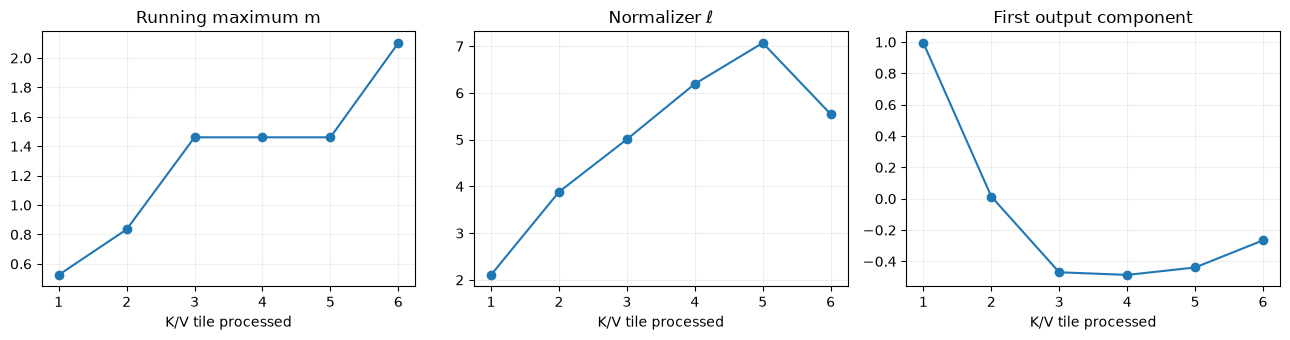

In [12]:
def trace_row(q, k, v, row=3, block_k=4, causal=False):
    n,d = q.shape
    m=-np.inf; ell=0.; acc=np.zeros(d,dtype=np.float64); history=[]
    for start in range(0,n,block_k):
        js=np.arange(start,min(n,start+block_k))
        if causal: js=js[js<=row]
        if js.size == 0: continue
        s=(k[js].astype(np.float64) @ q[row].astype(np.float64))/np.sqrt(d)
        next_m=max(m,float(s.max()))
        alpha=0. if not np.isfinite(m) else np.exp(m-next_m)
        w=np.exp(s-next_m)
        ell=alpha*ell+w.sum();acc=alpha*acc+w@v[js];m=next_m
        history.append((start,m,ell,acc.copy()/ell))
    return history

rng=np.random.default_rng(314)
qq,kk,vv=[rng.normal(size=(23,8)).astype(np.float32) for _ in range(3)]
h=trace_row(qq,kk,vv,row=20,block_k=4)
fig,ax=plt.subplots(1,3,figsize=(13,3.5))
steps=np.arange(1,len(h)+1)
ax[0].plot(steps,[x[1] for x in h],marker='o');ax[0].set_title('Running maximum m')
ax[1].plot(steps,[x[2] for x in h],marker='o');ax[1].set_title('Normalizer ℓ')
ax[2].plot(steps,[x[3][0] for x in h],marker='o');ax[2].set_title('First output component')
for a in ax:a.set_xlabel('K/V tile processed');a.grid(alpha=.2)
plt.tight_layout();plt.show()

## 7 — Contrast memory traffic / algorithm shape

Dense attention creates an $N\times N$ score array; our pedagogical fused kernel creates **none**. It uses a $BK$ score array and $d$ accumulator per active thread, **but does not reuse loaded K/V across query rows**. Therefore lower intermediate storage **does not guarantee lower runtime**.

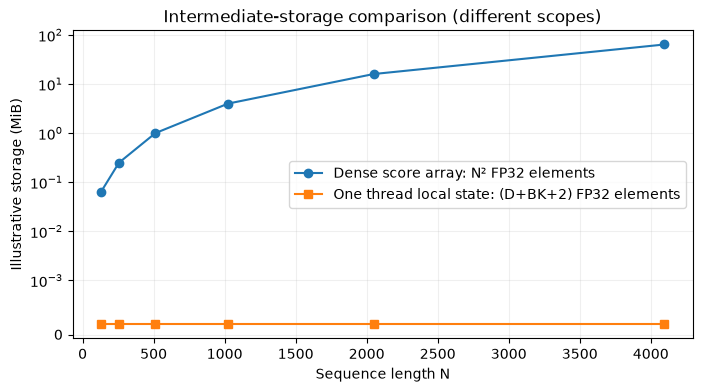

Caution: local state is per thread and may spill; this is NOT total GPU memory measurement.


In [13]:
Nvals=np.array([128,256,512,1024,2048,4096])
D=32;BK=16
# Illustrative per-head intermediate sizes (not measured process memory or cache footprint)
dense_scores=Nvals.astype(float)**2*4/1024**2
one_thread_state=np.full_like(dense_scores,(D+BK+2)*4/1024**2)
plt.figure(figsize=(8,4))
plt.plot(Nvals,dense_scores,'o-',label='Dense score array: N² FP32 elements')
plt.plot(Nvals,one_thread_state,'s-',label='One thread local state: (D+BK+2) FP32 elements')
plt.xlabel('Sequence length N');plt.ylabel('Illustrative storage (MiB)');plt.yscale('symlog',linthresh=.001)
plt.title('Intermediate-storage comparison (different scopes)')
plt.legend();plt.grid(alpha=.2);plt.show()
print('Caution: local state is per thread and may spill; this is NOT total GPU memory measurement.')

## 8 — Benchmark on your M5 (optional; no promised speedup)

Compare our **experimental** kernel with dense MLX attention. Because MLX uses lazy evaluation and Metal compilation is expensive, compile/warm up first, force execution each iteration, report medians, and use the same random inputs. This is a simple end-to-end stopwatch, not an isolated kernel profiler. Benchmarks intentionally use modest sizes because this unoptimized kernel may be very slow for long sequences.

N= 64: custom 0.646 ms; dense MLX 0.540 ms
N=128: custom 0.742 ms; dense MLX 0.609 ms
N=256: custom 1.150 ms; dense MLX 0.190 ms


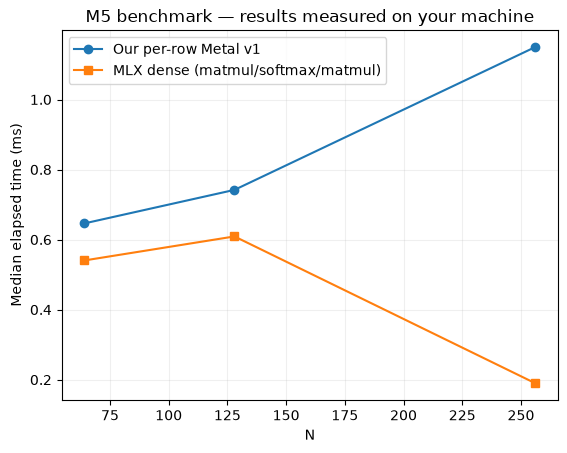

In [14]:
if MLX_OK:
    def mlx_dense(q,k,v):
        scores = (q @ mx.transpose(k)) * (q.shape[-1] ** -0.5)
        return mx.softmax(scores, axis=-1) @ v

    def timed_ms(call, repeats=7):
        y=call();mx.eval(y) # warmup + force compilation
        times=[]
        for _ in range(repeats):
            t0=time.perf_counter()
            y=call();mx.eval(y)
            times.append((time.perf_counter()-t0)*1000)
        return float(np.median(times))

    bench=[]
    for n in (64,128,256):
        rng=np.random.default_rng(n)
        qn,kn,vn=[rng.normal(size=(n,32)).astype(np.float32) for _ in range(3)]
        qm,km,vm=[mx.array(x) for x in (qn,kn,vn)]
        custom=timed_ms(lambda:flash_attention_metal(qm,km,vm,block_k=16))
        dense=timed_ms(lambda:mlx_dense(qm,km,vm))
        bench.append((n,custom,dense))
        print(f'N={n:>3}: custom {custom:.3f} ms; dense MLX {dense:.3f} ms')
    xs=[row[0] for row in bench]
    plt.plot(xs,[row[1] for row in bench],'o-',label='Our per-row Metal v1')
    plt.plot(xs,[row[2] for row in bench],'s-',label='MLX dense (matmul/softmax/matmul)')
    plt.xlabel('N');plt.ylabel('Median elapsed time (ms)');plt.title('M5 benchmark — results measured on your machine')
    plt.legend();plt.grid(alpha=.2);plt.show()
else:
    print('SKIPPED: benchmark requires Apple M5 + MLX Metal.')

## 9 — Limitations, exercises, and Notebook 05

### What we achieved
- A mathematically equivalent *forward-only* streaming attention algorithm with causal support.
- An actual **single fused custom Metal kernel** (not a sequence of high-level GPU operations), callable from Python/MLX.
- Tests for uneven sequence lengths and multiple score-tile sizes; optional latency experiment.

### What this is **not**
- Not a fully optimized FlashAttention-1 implementation: one thread per row means repeated K/V loads and scalar dot products.
- Not a universal attention API: no batch/head dimensions, head width beyond 64, FP16/BF16, different K and V head sizes, additive masks, dropout, gradients, or cross-attention.
- Not certified on M5 during authoring: Metal compilation and GPU performance must be tested on your Mac.

### Exercises
1. **Numerical stability:** shift Q and K and compare absolute/relative error. Why can a large *score* shift be safe for online softmax but overflow naïve softmax?
2. **Causal shortcut:** explain why `start > row` means the remainder of the key tiles can be skipped.
3. **Block size:** benchmark `BK=8`, `16`, `32`. Does reducing number of loops improve runtime? How might register use change?
4. **Memory reuse (next kernel):** design a threadgroup with \(B_q\) query rows that loads a \(B_k\times d\) K/V tile into **threadgroup memory**, synchronizes, then processes it cooperatively. Think about `threadgroup_barrier` and keeping all threads aligned.
5. **Correctness:** add an adversarial test where a late key generates the largest score and verify earlier accumulator contributions get rescaled.

### Notebook 05 preview: cooperative query tiling and threadgroup memory

We will transition from independent threads to shared on-chip tiles, the key hardware-aware optimization that distinguishes this educational v1 from optimized FlashAttention kernels.

**Documentation links:** [MLX API](https://ml-explore.github.io/mlx/build/html/python/_autosummary/mlx.core.fast.metal_kernel.html) · [Custom kernels guide](https://ml-explore.github.io/mlx/build/html/dev/custom_metal_kernels.html) · [Apple MLX talk](https://developer.apple.com/videos/play/wwdc2025/315/).